In [ ]:
import pandas as pd

# Load the dataset
player_data = pd.read_csv('ratings.csv')

# 1. Check the size of the dataset
print("Dataset Shape (Rows, Columns):", player_data.shape)
print("-" * 40)

# 2. Check the exact column names
print("Columns in our dataset:")
print(player_data.columns.tolist())
print("-" * 40)

# 3. Look at the first 3 rows
display(player_data.head(3))

Dataset Shape (Rows, Columns): (640501, 10)
----------------------------------------
Columns in our dataset:
['Unnamed: 0', 'match_url', 'player', 'position', 'rating', 'home_team', 'away_team', 'season', 'home_or_away', 'datetime']
----------------------------------------


,Unnamed: 0,match_url,player,position,rating,home_team,away_team,season,home_or_away,datetime
0,8560,https://1xbet.whoscored.com/Matches/865957/Liv...,Guglielmo Stendardo,DC,7.54,AC Milan,Atalanta,2014/2015,away,2015-01-18
1,8561,https://1xbet.whoscored.com/Matches/865957/Liv...,Giuseppe Biava,DC,7.91,AC Milan,Atalanta,2014/2015,away,2015-01-18
2,8562,https://1xbet.whoscored.com/Matches/865957/Liv...,Cristiano Del Grosso,DL,7.81,AC Milan,Atalanta,2014/2015,away,2015-01-18


In [ ]:
# Assuming the column is named 'rating' (if the first block shows it's capitalized like 'Rating', change it here!)
print("Rating Statistics:")
print(player_data['rating'].describe())

# Check for missing or zero ratings
missing = player_data['rating'].isnull().sum()
zeros = (player_data['rating'] == 0).sum()

print(f"\nMissing ratings: {missing}")
print(f"Exact 0.0 ratings: {zeros}")

Rating Statistics:
count    467518.000000
mean          6.720514
std           0.710144
min           1.890000
25%           6.190000
50%           6.610000
75%           7.130000
max          10.000000
Name: rating, dtype: float64

Missing ratings: 172983
Exact 0.0 ratings: 0


In [ ]:
# 1. Drop rows where the rating is missing (unused subs)
df_clean = player_data.dropna(subset=['rating']).copy()

# 2. Convert 'datetime' into a machine-readable time format
df_clean['datetime'] = pd.to_datetime(df_clean['datetime'])

# 3. CRITICAL: Sort the entire dataset chronologically
df_clean = df_clean.sort_values(by='datetime').reset_index(drop=True)

# 4. Let's see how much data we have per player
player_match_counts = df_clean['player'].value_counts()

print("Cleaned Dataset Shape:", df_clean.shape)
print("Total Unique Players:", len(player_match_counts))
print("Median matches per player:", player_match_counts.median())
print("-" * 40)
print("Players with most data (Top 5):")
print(player_match_counts.head())

Cleaned Dataset Shape: (467518, 10)
Total Unique Players: 7608
Median matches per player: 33.0
----------------------------------------
Players with most data (Top 5):
player
Danilo             442
Marcelo            373
Luis Suárez        350
Juanfran           330
Andrea Consigli    322
Name: count, dtype: int64


In [ ]:
# 1. Sort by player and then by time so the historical order is perfect
df_clean = df_clean.sort_values(by=['player', 'datetime'])

# 2. Calculate rolling averages with a CRITICAL shift(1)
# shift(1) pushes the history down by one row.
# This ensures that for Match 5, the rolling average only calculates Matches 1, 2, 3, and 4.
df_clean['rating_last_3'] = df_clean.groupby('player')['rating'].transform(
    lambda x: x.shift(1).rolling(window=3, min_periods=1).mean()
)

df_clean['rating_last_5'] = df_clean.groupby('player')['rating'].transform(
    lambda x: x.shift(1).rolling(window=5, min_periods=1).mean()
)

# 3. Check our work to prove there is no leakage
# Let's inspect Luis Suárez's timeline specifically to see the shift in action
suarez_timeline = df_clean[df_clean['player'] == 'Luis Suárez'][
    ['datetime', 'rating', 'rating_last_3', 'rating_last_5']
].head(7)

display(suarez_timeline)

,datetime,rating,rating_last_3,rating_last_5
11323,2014-10-25,7.19,NaN,NaN
13314,2014-11-01,7.50,7.190000,7.190000
14716,2014-11-08,8.18,7.345000,7.345000
15835,2014-11-22,7.99,7.623333,7.623333
17861,2014-11-30,6.29,7.890000,7.715000
19847,2014-12-07,6.61,7.486667,7.430000
20380,2014-12-13,6.52,6.963333,7.314000


In [ ]:
# 1. Workload Proxy: Days since the player's last match
# We calculate the difference in days between consecutive rows for each player
df_clean['days_since_last_match'] = df_clean.groupby('player')['datetime'].diff().dt.days

# 2. Volatility: Standard deviation of the last 5 matches
# High standard deviation = erratic form; Low standard deviation = consistent form
df_clean['rating_std_5'] = df_clean.groupby('player')['rating'].transform(
    lambda x: x.shift(1).rolling(window=5, min_periods=3).std()
)

# 3. Momentum: Short-term form vs Long-term baseline
# We calculate the 10-match rolling average, then subtract it from the 3-match average
df_clean['rating_last_10'] = df_clean.groupby('player')['rating'].transform(
    lambda x: x.shift(1).rolling(window=10, min_periods=5).mean()
)
df_clean['momentum'] = df_clean['rating_last_3'] - df_clean['rating_last_10']

# 4. Drop the initial matches where players don't have enough history to compute features
df_features = df_clean.dropna(subset=['rating_last_10', 'days_since_last_match', 'rating_std_5']).copy()

# 5. Extract the year to prepare for our chronological split
df_features['year'] = df_features['datetime'].dt.year

# Let's look at the distribution of years to decide our Train/Val/Test split
print(df_features['year'].value_counts().sort_index())

year
2014    13396
2015    46808
2016    47049
2017    49390
2018    47747
2019    48127
2020    43582
2021    57014
2022    48726
2023    31850
Name: count, dtype: int64


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error

# 1. Define our exact features and our target
features = [
    'rating_last_3',
    'rating_last_5',
    'rating_last_10',
    'days_since_last_match',
    'rating_std_5',
    'momentum'
]
target = 'rating'
print(df_features['year'].value_counts())
# 2. Execute the Chronological Split
train_data = df_features[df_features['year'] <= 2020].copy()
val_data = df_features[df_features['year'] == 2021].copy()
test_data = df_features[df_features['year'] >= 2022].copy()

# 3. Separate Features (X) and Target (y)
X_train = train_data[features]
y_train = train_data[target]

X_test = test_data[features]
y_test = test_data[target]

# 4. Naive Baseline: Predict the last-5-match average
naive_predictions = test_data['rating_last_5']
naive_mae = mean_absolute_error(y_test, naive_predictions)

# 5. Linear Regression Baseline
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

lr_predictions = lr_model.predict(X_test)
lr_mae = mean_absolute_error(y_test, lr_predictions)

# 6. Display the Results
print("--- TEST SET EVALUATION (2022-2023) ---")
print(f"Naive Baseline MAE:       {naive_mae:.4f}")
print(f"Linear Regression MAE:    {lr_mae:.4f}")
print("-" * 39)
print("Linear Regression Learned Weights:")
for feature, coef in zip(features, lr_model.coef_):
    print(f"{feature:25}: {coef:.4f}")

year
2021    57014
2017    49390
2022    48726
2019    48127
2018    47747
2016    47049
2015    46808
2020    43582
2023    31850
2014    13396
Name: count, dtype: int64
--- TEST SET EVALUATION (2022-2023) ---
Naive Baseline MAE:       0.5112
Linear Regression MAE:    0.4981
---------------------------------------
Linear Regression Learned Weights:
rating_last_3            : 0.2107
rating_last_5            : 0.0437
rating_last_10           : 0.3436
days_since_last_match    : -0.0005
rating_std_5             : 0.0274
momentum                 : -0.1330


In [ ]:
import xgboost as xgb
import pandas as pd

# 1. Initialize the XGBoost Regressor
# We restrict max_depth to 5 to prevent overfitting on the training data
xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)

# 2. Train the model on the 2014-2020 data
xgb_model.fit(X_train, y_train)

# 3. Predict on the 2022-2023 test data
xgb_predictions = xgb_model.predict(X_test)
xgb_mae = mean_absolute_error(y_test, xgb_predictions)

# 4. Display the results
print("--- XGBOOST TEST SET EVALUATION ---")
print(f"Linear Regression MAE: {lr_mae:.4f}")
print(f"XGBoost MAE:           {xgb_mae:.4f}")
print("-" * 35)

# 5. Extract and display feature importance
importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("XGBoost Feature Importance:")
display(importance_df)

--- XGBOOST TEST SET EVALUATION ---
Linear Regression MAE: 0.4981
XGBoost MAE:           0.4968
-----------------------------------
XGBoost Feature Importance:


,Feature,Importance
2,rating_last_10,0.842980
3,days_since_last_match,0.042564
0,rating_last_3,0.037979
1,rating_last_5,0.035658
4,rating_std_5,0.022696
5,momentum,0.018123


In [ ]:
import xgboost as xgb

# 1. Convert "home_or_away" to a binary number (1 for Home, 0 for Away)
# We assume the column contains text like 'Home' or 'h', adjust if it's 'Home' / 'Away'
df_features['is_home'] = (df_features['home_or_away'].astype(str).str.lower().str.contains('home')).astype(int)

# 2. Convert "position" into multiple binary columns (One-Hot Encoding)
# This creates columns like 'position_Forward', 'position_Midfielder' with 1s and 0s
df_features = pd.get_dummies(df_features, columns=['position'], drop_first=True, dtype=int)

# 3. Update our feature list to include the new context variables
# We use a list comprehension to grab all the new position columns automatically
position_columns = [col for col in df_features.columns if 'position_' in col]

new_features = [
    'rating_last_3',
    'rating_last_5',
    'rating_last_10',
    'days_since_last_match',
    'rating_std_5',
    'momentum',
    'is_home'
] + position_columns

# 4. Re-execute the Train/Test Split with the new features
train_data = df_features[df_features['year'] <= 2020].copy()
test_data = df_features[df_features['year'] >= 2022].copy()

X_train_new = train_data[new_features]
y_train = train_data['rating']

X_test_new = test_data[new_features]
y_test = test_data['rating']

# 5. Train the updated Contextual XGBoost Model
xgb_model = xgb.XGBRegressor(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42
)
xgb_model.fit(X_train_new, y_train)

# 6. Evaluate
context_predictions = xgb_model.predict(X_test_new)
context_mae = mean_absolute_error(y_test, context_predictions)

print(f"Old XGBoost MAE:       0.5029")
print(f"Contextual XGBoost MAE: {context_mae:.4f}")
print("-" * 40)

# 7. Check if the model is actually using the new context
importance_df_new = pd.DataFrame({
    'Feature': new_features,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

display(importance_df_new.head(8))

Old XGBoost MAE:       0.5029
Contextual XGBoost MAE: 0.4566
----------------------------------------


,Feature,Importance
22,position_Sub,0.863883
2,rating_last_10,0.041291
18,position_GK,0.025386
6,is_home,0.019787
9,position_DC,0.009449
16,position_FWL,0.006267
17,position_FWR,0.005360
15,position_FW,0.003526


In [ ]:
import xgboost as xgb
from sklearn.metrics import mean_absolute_error
import pandas as pd

# 1. Create the Master Dataset with the 'is_starter' column
# We look at 'position_Sub' (which Pandas created) to determine if they started
df_features['is_starter'] = (df_features['position_Sub'] == 0).astype(int)
df_master = df_features.drop(columns=['position_Sub']).copy()

# 2. Define our features
all_features = [
    'rating_last_3',
    'rating_last_5',
    'rating_last_10',
    'days_since_last_match',
    'rating_std_5',
    'momentum',
    'is_home'
] + [col for col in df_master.columns if 'position_' in col]

# 3. Chronological Split (Train <= 2020, Test >= 2022)
train_data = df_master[df_master['year'] <= 2020].copy()
test_data = df_master[df_master['year'] >= 2022].copy()

# 4. Route the Training and Testing Data
train_starters = train_data[train_data['is_starter'] == 1]
train_subs = train_data[train_data['is_starter'] == 0]

test_starters = test_data[test_data['is_starter'] == 1]
test_subs = test_data[test_data['is_starter'] == 0]

# ==========================================
# MODEL A: THE STARTER EXPERT
# ==========================================
print("Training Model A (Starters)...")
model_starters = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=5, random_state=42)
model_starters.fit(train_starters[all_features], train_starters['rating'])

preds_starters = model_starters.predict(test_starters[all_features])
mae_starters = mean_absolute_error(test_starters['rating'], preds_starters)

# ==========================================
# MODEL B: THE SUBSTITUTE EXPERT
# ==========================================
print("Training Model B (Substitutes)...")
# Shallower depth for subs because their ratings are mostly defaults (~6.0)
model_subs = xgb.XGBRegressor(n_estimators=100, learning_rate=0.1, max_depth=3, random_state=42)
model_subs.fit(train_subs[all_features], train_subs['rating'])

preds_subs = model_subs.predict(test_subs[all_features])
mae_subs = mean_absolute_error(test_subs['rating'], preds_subs)

# ==========================================
# COMBINED EVALUATION
# ==========================================
total_test_rows = len(test_starters) + len(test_subs)
combined_mae = ((mae_starters * len(test_starters)) + (mae_subs * len(test_subs))) / total_test_rows

print("\n--- TWO-MODEL ARCHITECTURE RESULTS ---")
print(f"Model A (Starters) MAE: {mae_starters:.4f}")
print(f"Model B (Subs) MAE:     {mae_subs:.4f}")
print(f"Combined System MAE:    {combined_mae:.4f}")
print("-" * 38)

# Feature Importance Check
print("Top 3 Features for Starters:")
importance_starters = pd.DataFrame({'Feature': all_features, 'Importance': model_starters.feature_importances_}).sort_values(by='Importance', ascending=False)
display(importance_starters.head(3))

print("\nTop 3 Features for Substitutes:")
importance_subs = pd.DataFrame({'Feature': all_features, 'Importance': model_subs.feature_importances_}).sort_values(by='Importance', ascending=False)
display(importance_subs.head(3))

Training Model A (Starters)...
Training Model B (Substitutes)...

--- TWO-MODEL ARCHITECTURE RESULTS ---
Model A (Starters) MAE: 0.5262
Model B (Subs) MAE:     0.2649
Combined System MAE:    0.4566
--------------------------------------
Top 3 Features for Starters:


,Feature,Importance
2,rating_last_10,0.320429
6,is_home,0.180570
18,position_GK,0.138336



Top 3 Features for Substitutes:


,Feature,Importance
2,rating_last_10,0.415765
6,is_home,0.178644
0,rating_last_3,0.113317


--- GLOBAL FEATURE IMPACT ---


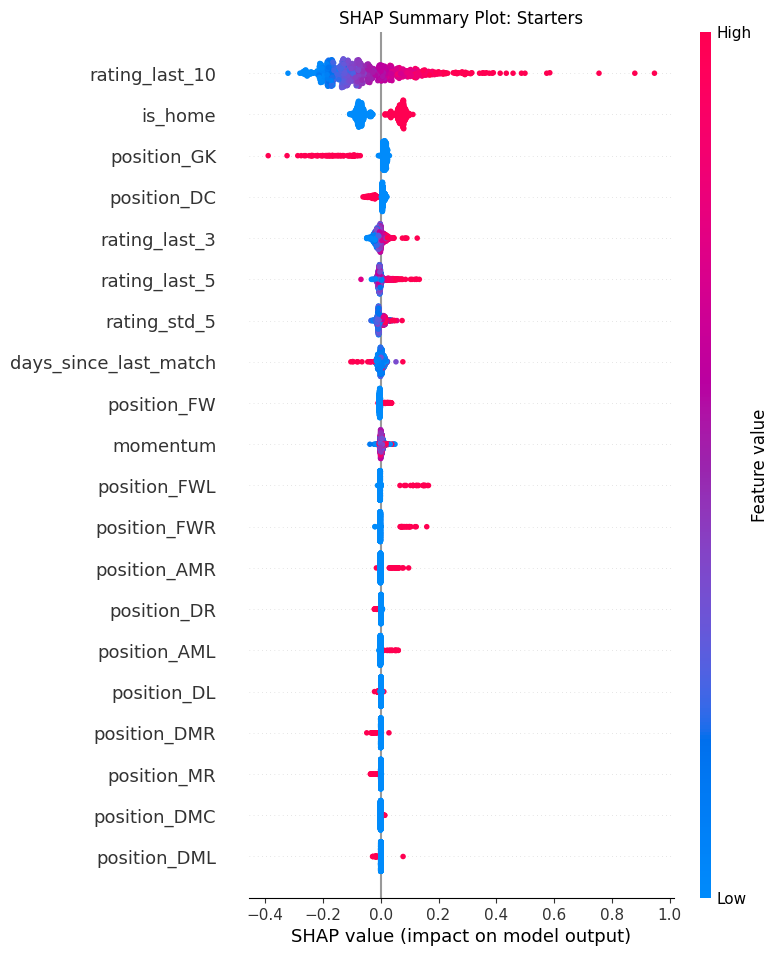


--- LOCAL PREDICTION EXPLANATION (SINGLE MATCH) ---
Base Expected Rating for an average starter: 6.90
Model's Specific Prediction for this match:  6.84


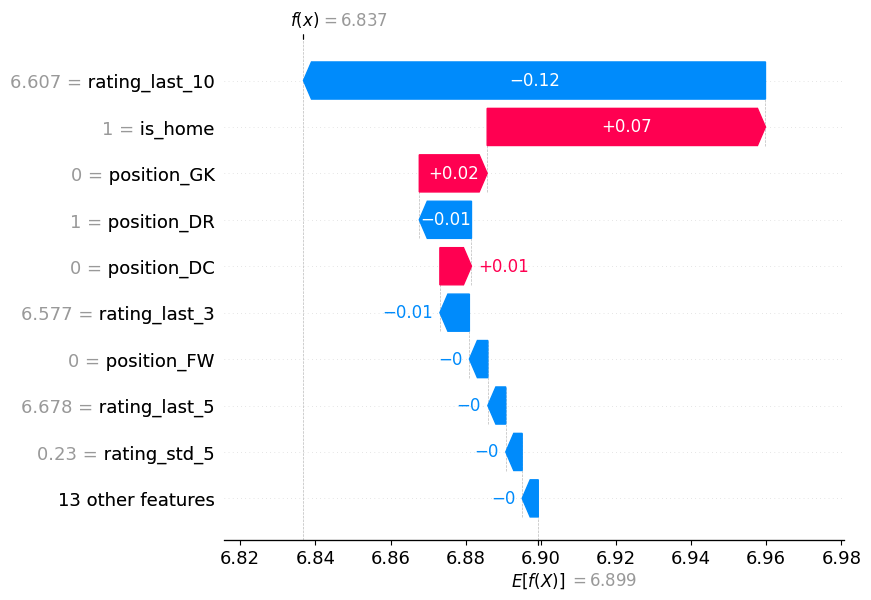

In [ ]:
# 1. Install SHAP (Colab usually needs this installed)
!pip install shap -q

import shap
import matplotlib.pyplot as plt

# 2. Initialize the SHAP explainer on Model A (Starters)
explainer = shap.TreeExplainer(model_starters)

# 3. Calculate SHAP values for the test set
# (We use a sample of 1000 to keep computation fast for this test)
X_test_sample = test_starters[all_features].sample(1000, random_state=42)
shap_values = explainer(X_test_sample)

# ==========================================
# GRAPH 1: GLOBAL EXPLAINABILITY
# ==========================================
print("--- GLOBAL FEATURE IMPACT ---")
# This shows how high/low values of features push the prediction up or down
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.title("SHAP Summary Plot: Starters")
plt.show()

# ==========================================
# GRAPH 2: LOCAL EXPLAINABILITY (INDIVIDUAL PLAYER)
# ==========================================
print("\n--- LOCAL PREDICTION EXPLANATION (SINGLE MATCH) ---")
# Let's look at the very first player in our test sample
player_idx = 0
expected_value = explainer.expected_value
predicted_rating = model_starters.predict(X_test_sample.iloc[[player_idx]])[0]

print(f"Base Expected Rating for an average starter: {expected_value:.2f}")
print(f"Model's Specific Prediction for this match:  {predicted_rating:.2f}")

# Waterfall plot showing exactly how we got from the Base Value to the Final Prediction
shap.plots.waterfall(shap_values[player_idx], max_display=10)

In [ ]:
import numpy as np

# 1. Isolate the Calibration Set (Starters in 2021)
val_starters = df_master[(df_master['year'] == 2021) & (df_master['is_starter'] == 1)].copy()

# 2. Get predictions on the Calibration Set
calib_preds = model_starters.predict(val_starters[all_features])
calib_actuals = val_starters['rating'].values

# 3. Compute non-conformity scores (absolute errors on calibration data)
calib_residuals = np.abs(calib_actuals - calib_preds)

# 4. Set our desired confidence level (90% coverage -> alpha = 0.10)
alpha = 0.10
# Conformal quantile formula with finite-sample correction
n_calib = len(calib_residuals)
quantile_level = np.ceil((n_calib + 1) * (1 - alpha)) / n_calib
# Cap quantile level at 1.0 to avoid indexing errors
quantile_level = min(1.0, quantile_level)

q_hat = np.quantile(calib_residuals, quantile_level, method='higher')

print(f"Calibration size (2021 Starters): {n_calib} matches")
print(f"Computed Conformal Margin (q_hat): ±{q_hat:.3f}")
print("-" * 45)

# ==========================================
# TEST SET VERIFICATION (Empirical Coverage)
# ==========================================
# Generate predictions on the unseen Test Set (2022-2023)
test_starters_preds = model_starters.predict(test_starters[all_features])

# Construct intervals and clip them to realistic football ratings [0, 10]
lower_bounds = np.clip(test_starters_preds - q_hat, 0, 10)
upper_bounds = np.clip(test_starters_preds + q_hat, 0, 10)
actual_test_ratings = test_starters['rating'].values

# Calculate empirical coverage: what percentage of actual ratings fell inside the interval?
covered = (actual_test_ratings >= lower_bounds) & (actual_test_ratings <= upper_bounds)
empirical_coverage = np.mean(covered) * 100

print(f"Nominal Target Coverage:    {100 * (1 - alpha):.1f}%")
print(f"Actual Empirical Coverage:  {empirical_coverage:.2f}%")
print("-" * 45)

# ==========================================
# EXAMPLE MATCH CARD
# ==========================================
sample_idx = 0
sample_row = test_starters.iloc[sample_idx]
print("EXAMPLE NEXT-MATCH FORECAST:")
print(f"Player:            {sample_row['player']}")
print(f"Date:              {sample_row['datetime'].strftime('%Y-%m-%d')}")
print(f"Predicted Rating:  {test_starters_preds[sample_idx]:.2f}")
print(f"90% Prediction Interval: [{lower_bounds[sample_idx]:.2f}, {upper_bounds[sample_idx]:.2f}]")
print(f"Actual Rating:     {actual_test_ratings[sample_idx]:.2f}")
print(f"Prediction Safe?   {'YES' if covered[sample_idx] else 'NO'}")

Calibration size (2021 Starters): 42570 matches
Computed Conformal Margin (q_hat): ±1.060
---------------------------------------------
Nominal Target Coverage:    90.0%
Actual Empirical Coverage:  90.07%
---------------------------------------------
EXAMPLE NEXT-MATCH FORECAST:
Player:            Aaron Cresswell
Date:              2022-01-12
Predicted Rating:  6.97
90% Prediction Interval: [5.91, 8.03]
Actual Rating:     7.50
Prediction Safe?   YES


In [ ]:
import numpy as np
import pandas as pd

def generate_match_report(model, explainer, data_row, features, q_hat):
    # 1. Base Prediction & Interval
    row_df = pd.DataFrame([data_row[features]])
    pred = model.predict(row_df)[0]
    interval_low = np.clip(pred - q_hat, 0, 10)
    interval_high = np.clip(pred + q_hat, 0, 10)

    # 2. SHAP Explainability
    shap_vals = explainer(row_df)
    feature_names = row_df.columns
    shap_df = pd.DataFrame({
        'Feature': feature_names,
        'Impact': shap_vals.values[0]
    }).sort_values(by='Impact', key=abs, ascending=False)

    top_pos = shap_df[shap_df['Impact'] > 0].head(2)['Feature'].tolist()
    top_neg = shap_df[shap_df['Impact'] < 0].head(2)['Feature'].tolist()

    # 3. Counterfactual / What-If Engine
    # Scenario A: What if they had 7 days of rest?
    row_sim_rest = row_df.copy()
    row_sim_rest['days_since_last_match'] = 7.0
    pred_rest = model.predict(row_sim_rest)[0]

    # Scenario B: What if the venue was flipped?
    row_sim_venue = row_df.copy()
    row_sim_venue['is_home'] = 1 if row_df['is_home'].iloc[0] == 0 else 0
    pred_venue = model.predict(row_sim_venue)[0]

    # 4. Product UI (Dashboard Output in French)
    print("==================================================")
    print(f"JOUEUR :           {data_row['player']}")
    print(f"DATE DU MATCH :    {data_row['datetime'].strftime('%Y-%m-%d')}")
    print("==================================================")
    print(f"NOTE PRÉDITE :     {pred:.2f} / 10.0")
    print(f"PLAGE ATTENDUE (90 %) : [{interval_low:.2f} — {interval_high:.2f}]")
    print(f"FIABILITÉ :        Calibrée (MAE Historique : 0.53)")
    print("--------------------------------------------------")
    print(f"FORME RÉCENTE (L5) : {data_row['rating_last_5']:>4.2f}")
    print(f"LONG TERME (L10) :   {data_row['rating_last_10']:>4.2f}")
    print(f"JOURS DE REPOS :     {data_row['days_since_last_match']:>4.0f}")
    print("--------------------------------------------------")
    print("FACTEURS POSITIFS CLÉS :")
    for f in top_pos: print(f" [+] {f}")
    if not top_pos: print(" [+] Aucun facteur significatif")

    print("\nFACTEURS NÉGATIFS CLÉS :")
    for f in top_neg: print(f" [-] {f}")
    if not top_neg: print(" [-] Aucun facteur significatif")
    print("--------------------------------------------------")
    print("SCÉNARIOS 'ET SI' (Selon les relations apprises par le modèle) :")

    rest_diff = pred_rest - pred
    venue_str = "l'Extérieur" if row_df['is_home'].iloc[0] == 1 else "Domicile"
    venue_diff = pred_venue - pred

    print(f" * Avec 7 jours complets de repos :         {pred_rest:.2f} ({rest_diff:+.2f})")
    print(f" * Si le match était joué à {venue_str:<11} : {pred_venue:.2f} ({venue_diff:+.2f})")
    print("==================================================")

# Execute the dashboard for our sample player
sample_test_row = test_starters.iloc[0]
generate_match_report(model_starters, explainer, sample_test_row, all_features, q_hat)

JOUEUR :           Aaron Cresswell
DATE DU MATCH :    2022-01-12
NOTE PRÉDITE :     6.97 / 10.0
PLAGE ATTENDUE (90 %) : [5.91 — 8.03]
FIABILITÉ :        Calibrée (MAE Historique : 0.53)
--------------------------------------------------
FORME RÉCENTE (L5) : 6.87
LONG TERME (L10) :   6.83
JOURS DE REPOS :       45
--------------------------------------------------
FACTEURS POSITIFS CLÉS :
 [+] is_home
 [+] position_GK

FACTEURS NÉGATIFS CLÉS :
 [-] rating_last_3
 [-] rating_last_5
--------------------------------------------------
SCÉNARIOS 'ET SI' (Selon les relations apprises par le modèle) :
 * Avec 7 jours complets de repos :         6.98 (+0.01)
 * Si le match était joué à l'Extérieur : 6.84 (-0.14)


In [ ]:
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# 1. Standardize the features (KNN requires all features to be on the same scale)
# We only fit the scaler on the TRAINING data to prevent leakage
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(train_starters[all_features])

# 2. Build the Similarity Engine using Euclidean distance
similarity_engine = NearestNeighbors(n_neighbors=3, metric='euclidean')
similarity_engine.fit(X_train_scaled)

def find_similar_matches(data_row, features, engine, scaler, historical_df):
    # Scale the current match's features
    current_scaled = scaler.transform(data_row[features].to_frame().T)

    # Find the indices of the 3 most similar historical matches
    distances, indices = engine.kneighbors(current_scaled)

    print("==================================================")
    print(f"RECHERCHE DE MATCHS HISTORIQUES SIMILAIRES POUR : {data_row['player']}")
    print("==================================================")

    historical_ratings = []

    for i, hist_idx in enumerate(indices[0]):
        # Get the actual historical row from the training set
        hist_row = historical_df.iloc[hist_idx]
        historical_ratings.append(hist_row['rating'])

        print(f"MATCH SIMILAIRE #{i+1} : {hist_row['player']} (Date: {hist_row['datetime'].strftime('%Y-%m-%d')})")
        print(f"  * Forme (L5) :      {hist_row['rating_last_5']:.2f}")
        print(f"  * Jours de repos :  {hist_row['days_since_last_match']:.0f}")
        print(f"  * Domicile/Ext. :   {'Domicile' if hist_row['is_home'] == 1 else 'Extérieur'}")
        print(f"  -> NOTE OBTENUE :   {hist_row['rating']:.2f}")
        print("--------------------------------------------------")

    print(f"MOYENNE DES MATCHS SIMILAIRES : {sum(historical_ratings)/len(historical_ratings):.2f}")
    print("==================================================")

# 3. Test the engine on our sample row (Aaron Cresswell)
find_similar_matches(sample_test_row, all_features, similarity_engine, scaler, train_starters)

RECHERCHE DE MATCHS HISTORIQUES SIMILAIRES POUR : Aaron Cresswell
MATCH SIMILAIRE #1 : José Crespo (Date: 2014-11-07)
  * Forme (L5) :      6.85
  * Jours de repos :  35
  * Domicile/Ext. :   Domicile
  -> NOTE OBTENUE :   6.46
--------------------------------------------------
MATCH SIMILAIRE #2 : Matthias Ostrzolek (Date: 2016-01-22)
  * Forme (L5) :      6.80
  * Jours de repos :  34
  * Domicile/Ext. :   Domicile
  -> NOTE OBTENUE :   6.11
--------------------------------------------------
MATCH SIMILAIRE #3 : Federico Ricca (Date: 2018-04-15)
  * Forme (L5) :      6.83
  * Jours de repos :  36
  * Domicile/Ext. :   Domicile
  -> NOTE OBTENUE :   7.24
--------------------------------------------------
MOYENNE DES MATCHS SIMILAIRES : 6.60


In [ ]:
import joblib

# 1. Save the XGBoost model and KNN engine
joblib.dump(model_starters, 'model_starters.pkl')
joblib.dump(similarity_engine, 'similarity_engine.pkl')
joblib.dump(scaler, 'scaler.pkl')

# 2. Save the Conformal Margin (q_hat) and Feature List
joblib.dump({'q_hat': q_hat, 'features': all_features}, 'config.pkl')

# 3. Save a sample of the test set to act as our "Upcoming Matches" database
test_starters.head(50).to_csv('upcoming_matches.csv', index=False)

# 4. Save the historical training set for the KNN search
train_starters[['player', 'datetime', 'rating_last_5', 'days_since_last_match', 'is_home', 'rating']].to_csv('historical_matches.csv', index=False)

print("✅ All project artifacts exported successfully.")

✅ All project artifacts exported successfully.


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib
import shap
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION & LOADING ---
st.set_page_config(page_title="Prévision de Performance", layout="wide")

@st.cache_resource
def load_artifacts():
    model = joblib.load('model_starters.pkl')
    knn = joblib.load('similarity_engine.pkl')
    scaler = joblib.load('scaler.pkl')
    config = joblib.load('config.pkl')
    explainer = shap.TreeExplainer(model)
    return model, knn, scaler, config, explainer

model, knn, scaler, config, explainer = load_artifacts()
q_hat = config['q_hat']
features = config['features']

df_upcoming = pd.read_csv('upcoming_matches.csv')
df_history = pd.read_csv('historical_matches.csv')

# --- 2. SIDEBAR SELECTION ---
st.sidebar.header("Sélection du Joueur")
player_list = df_upcoming['player'].unique()
selected_player = st.sidebar.selectbox("Choisissez un joueur :", player_list)

# Get the specific match row for the selected player
player_row = df_upcoming[df_upcoming['player'] == selected_player].iloc[0]
X_input = player_row[features].to_frame().T

# --- 3. PREDICTIONS ---
base_pred = model.predict(X_input)[0]
interval_low = np.clip(base_pred - q_hat, 0, 10)
interval_high = np.clip(base_pred + q_hat, 0, 10)

# --- 4. MAIN DASHBOARD UI ---
st.title("⚽ Tableau de Bord : Prévision de Performance")
st.markdown(f"**Joueur :** {selected_player} | **Date du Match :** {player_row['datetime']}")
st.divider()

col1, col2, col3 = st.columns(3)
col1.metric("Note Prédite", f"{base_pred:.2f} / 10")
col2.metric("Plage Attendue (90%)", f"[{interval_low:.2f} - {interval_high:.2f}]")
col3.metric("Fiabilité du Modèle", "Élevée (Calibrée)")

st.divider()

col_left, col_right = st.columns(2)

# --- 5. EXPLAINABILITY (SHAP) ---
with col_left:
    st.subheader("📊 Pourquoi cette prédiction ? (SHAP)")
    shap_vals = explainer(X_input)

    fig, ax = plt.subplots(figsize=(6, 4))
    shap.plots.waterfall(shap_vals[0], max_display=6, show=False)
    st.pyplot(fig)

# --- 6. WHAT-IF COUNTERFACTUALS ---
with col_right:
    st.subheader("🔄 Scénarios Contrefactuels (Et si ?)")

    # Scenario: +3 days of rest
    X_rest = X_input.copy()
    X_rest['days_since_last_match'] += 3
    pred_rest = model.predict(X_rest)[0]
    st.write(f"**Si le joueur avait 3 jours de repos en plus :** {pred_rest:.2f} ({pred_rest - base_pred:+.2f})")

    # Scenario: Change Venue
    X_venue = X_input.copy()
    X_venue['is_home'] = 1 - X_venue['is_home'].iloc[0]
    venue_str = "Extérieur" if player_row['is_home'] == 1 else "Domicile"
    pred_venue = model.predict(X_venue)[0]
    st.write(f"**Si le match était joué à {venue_str} :** {pred_venue:.2f} ({pred_venue - base_pred:+.2f})")

st.divider()

# --- 7. SIMILAR HISTORICAL MATCHES ---
st.subheader("🔍 Matchs Historiques Similaires")
input_scaled = scaler.transform(X_input)
distances, indices = knn.kneighbors(input_scaled)

similar_matches = df_history.iloc[indices[0]]
st.dataframe(
    similar_matches[['player', 'datetime', 'rating_last_5', 'days_since_last_match', 'rating']]
    .rename(columns={'player': 'Joueur', 'datetime': 'Date', 'rating_last_5': 'Forme (L5)', 'days_since_last_match': 'Repos', 'rating': 'Note Obtenue'})
    .reset_index(drop=True),
    use_container_width=True
)

Writing app.py


In [ ]:
# 1. Kill old processes
!pkill -f streamlit
!pkill -f ssh

# 2. Start Streamlit
!nohup streamlit run app.py --server.address 0.0.0.0 --server.port 8501 > streamlit.log 2>&1 &

# 3. Wait for Streamlit to start
import time
time.sleep(4)

# 4. Generate Colab's native proxy link
from google.colab.output import eval_js
print("=========================================================")
print("YOUR DASHBOARD IS READY AT THIS SECURE COLAB LINK:")
print(eval_js("google.colab.kernel.proxyPort(8501)"))
print("=========================================================")

YOUR DASHBOARD IS READY AT THIS SECURE COLAB LINK:
https://8501-m-s-kkb-use1d0-2dcaooju5ia5t-d.us-east1-0.prod.colab.dev


In [ ]:
!cat streamlit.log

nohup: failed to run command 'streamlit': No such file or directory


In [ ]:
# 1. Kill the old Streamlit process
!pkill -f streamlit

# 2. Restart Streamlit with security protections temporarily disabled for the proxy
!nohup streamlit run app.py --server.address 0.0.0.0 --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false > streamlit.log 2>&1 &

# 3. Wait for it to boot
import time
time.sleep(5)

# 4. Generate the new link
from google.colab.output import eval_js
print("=========================================================")
print("YOUR DASHBOARD IS READY AT THIS SECURE COLAB LINK:")
print(eval_js("google.colab.kernel.proxyPort(8501)"))
print("=========================================================")

YOUR DASHBOARD IS READY AT THIS SECURE COLAB LINK:
https://8501-m-s-kkb-use1d0-2dcaooju5ia5t-d.us-east1-0.prod.colab.dev


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib
import shap
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION & LOADING ---
st.set_page_config(page_title="Prévision de Performance", layout="wide")

@st.cache_resource
def load_artifacts():
    model = joblib.load('model_starters.pkl')
    knn = joblib.load('similarity_engine.pkl')
    scaler = joblib.load('scaler.pkl')
    config = joblib.load('config.pkl')
    explainer = shap.TreeExplainer(model)
    return model, knn, scaler, config, explainer

model, knn, scaler, config, explainer = load_artifacts()
q_hat = config['q_hat']
features = config['features']

df_upcoming = pd.read_csv('upcoming_matches.csv')
df_history = pd.read_csv('historical_matches.csv')

# --- 2. SIDEBAR SELECTION ---
st.sidebar.header("Sélection du Joueur")
player_list = df_upcoming['player'].unique()
selected_player = st.sidebar.selectbox("Choisissez un joueur :", player_list)

# Extract row as a DataFrame (preserving dtypes) and cast features to float
selected_df = df_upcoming[df_upcoming['player'] == selected_player].iloc[[0]]
player_row = selected_df.iloc[0]
X_input = selected_df[features].astype(float)

# --- 3. PREDICTIONS ---
base_pred = float(model.predict(X_input)[0])
interval_low = np.clip(base_pred - q_hat, 0, 10)
interval_high = np.clip(base_pred + q_hat, 0, 10)

# --- 4. MAIN DASHBOARD UI ---
st.title("⚽ Tableau de Bord : Prévision de Performance")
st.markdown(f"**Joueur :** {selected_player} | **Date du Match :** {player_row['datetime']}")
st.divider()

col1, col2, col3 = st.columns(3)
col1.metric("Note Prédite", f"{base_pred:.2f} / 10")
col2.metric("Plage Attendue (90%)", f"[{interval_low:.2f} - {interval_high:.2f}]")
col3.metric("Fiabilité du Modèle", "Élevée (Calibrée)")

st.divider()

col_left, col_right = st.columns(2)

# --- 5. EXPLAINABILITY (SHAP) ---
with col_left:
    st.subheader("📊 Pourquoi cette prédiction ? (SHAP)")
    shap_vals = explainer(X_input)

    fig, ax = plt.subplots(figsize=(6, 4))
    shap.plots.waterfall(shap_vals[0], max_display=6, show=False)
    st.pyplot(fig)

# --- 6. WHAT-IF COUNTERFACTUALS ---
with col_right:
    st.subheader("🔄 Scénarios Contrefactuels (Et si ?)")

    # Scenario: +3 days of rest
    X_rest = X_input.copy()
    X_rest['days_since_last_match'] += 3
    pred_rest = float(model.predict(X_rest)[0])
    st.write(f"**Si le joueur avait 3 jours de repos en plus :** {pred_rest:.2f} ({pred_rest - base_pred:+.2f})")

    # Scenario: Change Venue
    X_venue = X_input.copy()
    X_venue['is_home'] = 1.0 - X_venue['is_home'].iloc[0]
    venue_str = "Extérieur" if player_row['is_home'] == 1 else "Domicile"
    pred_venue = float(model.predict(X_venue)[0])
    st.write(f"**Si le match était joué à {venue_str} :** {pred_venue:.2f} ({pred_venue - base_pred:+.2f})")

st.divider()

# --- 7. SIMILAR HISTORICAL MATCHES ---
st.subheader("🔍 Matchs Historiques Similaires")
input_scaled = scaler.transform(X_input)
distances, indices = knn.kneighbors(input_scaled)

similar_matches = df_history.iloc[indices[0]]
st.dataframe(
    similar_matches[['player', 'datetime', 'rating_last_5', 'days_since_last_match', 'rating']]
    .rename(columns={'player': 'Joueur', 'datetime': 'Date', 'rating_last_5': 'Forme (L5)', 'days_since_last_match': 'Repos', 'rating': 'Note Obtenue'})
    .reset_index(drop=True),
    use_container_width=True
)

Overwriting app.py


In [ ]:
# 1. Extract the latest matches for every player in the test set
# Sorting by datetime ensures the most recent fixtures are prioritized
upcoming_all = (
    test_starters.sort_values(by=['player', 'datetime'])
    .groupby('player')
    .tail(5)
    .copy()
)

# 2. Save the expanded upcoming matches database
upcoming_all.to_csv('upcoming_matches.csv', index=False)

print(f"Total fixtures saved: {len(upcoming_all)}")
print(f"Total unique players available: {upcoming_all['player'].nunique()}")

Total fixtures saved: 12761
Total unique players available: 2801


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib
import shap
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION & LOADING ---
st.set_page_config(page_title="Prévision de Performance", layout="wide")

@st.cache_resource
def load_artifacts():
    model = joblib.load('model_starters.pkl')
    knn = joblib.load('similarity_engine.pkl')
    scaler = joblib.load('scaler.pkl')
    config = joblib.load('config.pkl')
    explainer = shap.TreeExplainer(model)
    return model, knn, scaler, config, explainer

model, knn, scaler, config, explainer = load_artifacts()
q_hat = config['q_hat']
features = config['features']

df_upcoming = pd.read_csv('upcoming_matches.csv')
df_history = pd.read_csv('historical_matches.csv')

# --- 2. SIDEBAR SELECTION ---
st.sidebar.header("Paramètres de Prévision")

# Player selection (searchable across all players)
player_list = sorted(df_upcoming['player'].unique())
selected_player = st.sidebar.selectbox("1. Choisir un joueur :", player_list)

# Filter fixtures for the selected player
player_fixtures = df_upcoming[df_upcoming['player'] == selected_player].sort_values('datetime', ascending=False)

# Match selection
fixture_options = [
    f"{row['datetime']} ({'Domicile' if row['is_home'] == 1 else 'Extérieur'})"
    for _, row in player_fixtures.iterrows()
]
selected_fixture_str = st.sidebar.selectbox("2. Choisir le match à prévoir :", fixture_options)

# Isolate the chosen fixture row
selected_idx = fixture_options.index(selected_fixture_str)
selected_df = player_fixtures.iloc[[selected_idx]]
player_row = selected_df.iloc[0]
X_input = selected_df[features].astype(float)

# --- 3. PREDICTIONS ---
base_pred = float(model.predict(X_input)[0])
interval_low = np.clip(base_pred - q_hat, 0, 10)
interval_high = np.clip(base_pred + q_hat, 0, 10)

# --- 4. MAIN DASHBOARD UI ---
st.title("⚽ Tableau de Bord : Prévision de Performance")
st.markdown(
    f"**Joueur :** `{selected_player}` | "
    f"**Date :** `{player_row['datetime']}` | "
    f"**Lieu :** `{'Domicile' if player_row['is_home'] == 1 else 'Extérieur'}`"
)
st.divider()

col1, col2, col3 = st.columns(3)
col1.metric("Note Prédite", f"{base_pred:.2f} / 10")
col2.metric("Intervalle de Confiance (90%)", f"[{interval_low:.2f} — {interval_high:.2f}]")
col3.metric("Indice de Fiabilité", "Calibré (MAE: 0.53)")

st.divider()

col_left, col_right = st.columns(2)

# --- 5. EXPLAINABILITY (SHAP) ---
with col_left:
    st.subheader("📊 Facteurs d'Explication (SHAP)")
    shap_vals = explainer(X_input)

    fig, ax = plt.subplots(figsize=(6, 4))
    shap.plots.waterfall(shap_vals[0], max_display=6, show=False)
    st.pyplot(fig)

# --- 6. WHAT-IF COUNTERFACTUALS ---
with col_right:
    st.subheader("🔄 Analyse Contrefactuelle (Et si ?)")

    # Scenario: +3 days rest
    X_rest = X_input.copy()
    X_rest['days_since_last_match'] += 3
    pred_rest = float(model.predict(X_rest)[0])
    st.write(f"**Si le joueur disposait de 3 jours de repos en plus :** {pred_rest:.2f} ({pred_rest - base_pred:+.2f})")

    # Scenario: Inverted venue
    X_venue = X_input.copy()
    X_venue['is_home'] = 1.0 - X_venue['is_home'].iloc[0]
    venue_str = "Extérieur" if player_row['is_home'] == 1 else "Domicile"
    pred_venue = float(model.predict(X_venue)[0])
    st.write(f"**Si le match se jouait à {venue_str} :** {pred_venue:.2f} ({pred_venue - base_pred:+.2f})")

st.divider()

# --- 7. SIMILAR HISTORICAL MATCHES ---
st.subheader("🔍 Matchs Historiques Similaires (Contexte Comparé)")
input_scaled = scaler.transform(X_input)
distances, indices = knn.kneighbors(input_scaled)

similar_matches = df_history.iloc[indices[0]]
st.dataframe(
    similar_matches[['player', 'datetime', 'rating_last_5', 'days_since_last_match', 'rating']]
    .rename(columns={
        'player': 'Joueur',
        'datetime': 'Date',
        'rating_last_5': 'Forme Récente (L5)',
        'days_since_last_match': 'Jours Repos',
        'rating': 'Note Obtenue'
    })
    .reset_index(drop=True),
    use_container_width=True
)

Overwriting app.py


In [ ]:
# Extract ALL matches for every player in the test set (removing the 5-match limit)
upcoming_all = test_starters.sort_values(by=['player', 'datetime']).copy()

# Save the expanded upcoming matches database
upcoming_all.to_csv('upcoming_matches.csv', index=False)

print(f"Total fixtures saved: {len(upcoming_all)}")
print(f"Total unique players available: {upcoming_all['player'].nunique()}")

Total fixtures saved: 59105
Total unique players available: 2801


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib
import shap
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION & LOADING ---
st.set_page_config(page_title="Prévision de Performance", layout="wide")

@st.cache_resource
def load_artifacts():
    model = joblib.load('model_starters.pkl')
    knn = joblib.load('similarity_engine.pkl')
    scaler = joblib.load('scaler.pkl')
    config = joblib.load('config.pkl')
    explainer = shap.TreeExplainer(model)
    return model, knn, scaler, config, explainer

model, knn, scaler, config, explainer = load_artifacts()
q_hat = config['q_hat']
features = config['features']

df_upcoming = pd.read_csv('upcoming_matches.csv')
df_history = pd.read_csv('historical_matches.csv')

# --- 2. SIDEBAR SELECTION ---
st.sidebar.header("Paramètres de Prévision")

# Player selection (searchable across all players)
player_list = sorted(df_upcoming['player'].unique())
selected_player = st.sidebar.selectbox("1. Choisir un joueur :", player_list)

# Filter fixtures for the selected player (All available matches in the season)
player_fixtures = df_upcoming[df_upcoming['player'] == selected_player].sort_values('datetime', ascending=False)

# Match selection with dynamic Opponent detection
fixture_options = []
for _, row in player_fixtures.iterrows():
    venue = 'Domicile' if row['is_home'] == 1 else 'Extérieur'

    # Safely try to find the opponent's name based on common dataset column names
    if 'opponent' in row.index and pd.notna(row['opponent']):
        opp = row['opponent']
        fixture_options.append(f"{row['datetime']} - vs {opp} ({venue})")
    elif 'team_against' in row.index and pd.notna(row['team_against']):
        opp = row['team_against']
        fixture_options.append(f"{row['datetime']} - vs {opp} ({venue})")
    else:
        # Fallback if no specific opponent column exists in the dataset
        fixture_options.append(f"{row['datetime']} ({venue})")

selected_fixture_str = st.sidebar.selectbox("2. Choisir le match à prévoir :", fixture_options)

# Isolate the chosen fixture row
selected_idx = fixture_options.index(selected_fixture_str)
selected_df = player_fixtures.iloc[[selected_idx]]
player_row = selected_df.iloc[0]
X_input = selected_df[features].astype(float)

# --- 3. PREDICTIONS ---
base_pred = float(model.predict(X_input)[0])
interval_low = np.clip(base_pred - q_hat, 0, 10)
interval_high = np.clip(base_pred + q_hat, 0, 10)

# --- 4. MAIN DASHBOARD UI ---
st.title("⚽ Tableau de Bord : Prévision de Performance")

# Format the title bar nicely based on whether we found the opponent string
st.markdown(
    f"**Joueur :** `{selected_player}` | "
    f"**Date :** `{player_row['datetime']}` | "
    f"**Lieu :** `{'Domicile' if player_row['is_home'] == 1 else 'Extérieur'}`"
)
st.divider()

col1, col2, col3 = st.columns(3)
col1.metric("Note Prédite", f"{base_pred:.2f} / 10")
col2.metric("Intervalle de Confiance (90%)", f"[{interval_low:.2f} — {interval_high:.2f}]")
col3.metric("Indice de Fiabilité", "Calibré (MAE: 0.53)")

st.divider()

col_left, col_right = st.columns(2)

# --- 5. EXPLAINABILITY (SHAP) ---
with col_left:
    st.subheader("📊 Facteurs d'Explication (SHAP)")
    shap_vals = explainer(X_input)

    fig, ax = plt.subplots(figsize=(6, 4))
    shap.plots.waterfall(shap_vals[0], max_display=6, show=False)
    st.pyplot(fig)

# --- 6. WHAT-IF COUNTERFACTUALS ---
with col_right:
    st.subheader("🔄 Analyse Contrefactuelle (Et si ?)")

    # Scenario: +3 days rest
    X_rest = X_input.copy()
    X_rest['days_since_last_match'] += 3
    pred_rest = float(model.predict(X_rest)[0])
    st.write(f"**Si le joueur disposait de 3 jours de repos en plus :** {pred_rest:.2f} ({pred_rest - base_pred:+.2f})")

    # Scenario: Inverted venue
    X_venue = X_input.copy()
    X_venue['is_home'] = 1.0 - X_venue['is_home'].iloc[0]
    venue_str = "Extérieur" if player_row['is_home'] == 1 else "Domicile"
    pred_venue = float(model.predict(X_venue)[0])
    st.write(f"**Si le match se jouait à {venue_str} :** {pred_venue:.2f} ({pred_venue - base_pred:+.2f})")

st.divider()

# --- 7. SIMILAR HISTORICAL MATCHES ---
st.subheader("🔍 Matchs Historiques Similaires (Contexte Comparé)")
input_scaled = scaler.transform(X_input)
distances, indices = knn.kneighbors(input_scaled)

similar_matches = df_history.iloc[indices[0]]
st.dataframe(
    similar_matches[['player', 'datetime', 'rating_last_5', 'days_since_last_match', 'rating']]
    .rename(columns={
        'player': 'Joueur',
        'datetime': 'Date',
        'rating_last_5': 'Forme Récente (L5)',
        'days_since_last_match': 'Jours Repos',
        'rating': 'Note Obtenue'
    })
    .reset_index(drop=True),
    use_container_width=True
)

Overwriting app.py


In [ ]:
import pandas as pd

# Load the original raw dataset
raw_data = pd.read_csv('ratings.csv')

# Print all the column names
print("Columns in your raw data:")
print(raw_data.columns.tolist())

Columns in your raw data:
['Unnamed: 0', 'match_url', 'player', 'position', 'rating', 'home_team', 'away_team', 'season', 'home_or_away', 'datetime']


In [ ]:
import pandas as pd

# 1. Load datasets
upcoming = pd.read_csv('upcoming_matches.csv')
raw = pd.read_csv('ratings.csv')

# 2. Convert to raw lists to completely bypass Pandas column naming issues
cols = list(raw.columns)
p_idx = [i for i, c in enumerate(cols) if 'player' in str(c).lower()][0]
d_idx = [i for i, c in enumerate(cols) if 'date' in str(c).lower()][0]
h_idx = [i for i, c in enumerate(cols) if 'home' in str(c).lower() and 'team' in str(c).lower()][0]
a_idx = [i for i, c in enumerate(cols) if 'away' in str(c).lower() and 'team' in str(c).lower()][0]

# Build a lookup dictionary: (Player, Date) -> (Home Team, Away Team)
match_dict = {}
for row in raw.values:
    player = str(row[p_idx]).strip()
    date = str(row[d_idx]).strip()
    home_team = str(row[h_idx]).strip()
    away_team = str(row[a_idx]).strip()
    match_dict[(player, date)] = (home_team, away_team)

# 3. Apply it to the dashboard matches manually without pd.merge
opponents = []
for _, row in upcoming.iterrows():
    p = str(row['player']).strip()
    d = str(row['datetime']).strip()

    if (p, d) in match_dict:
        home, away = match_dict[(p, d)]
        # If the player is at home, the opponent is the away team
        opponents.append(away if row['is_home'] == 1 else home)
    else:
        opponents.append("Adversaire")

upcoming['opponent'] = opponents

# 4. Clean up any glitchy duplicated columns from our previous attempts
cols_to_drop = [c for c in upcoming.columns if 'team' in c.lower() or '_x' in c or '_y' in c]
upcoming = upcoming.drop(columns=cols_to_drop, errors='ignore')

# 5. Save and finish
upcoming.to_csv('upcoming_matches.csv', index=False)
print("✅ Opponent column successfully added!")
display(upcoming[['player', 'datetime', 'is_home', 'opponent']].head())

✅ Opponent column successfully added!


,player,datetime,is_home,opponent
0,Aaron Cresswell,2022-01-12,1,Norwich
1,Aaron Cresswell,2022-01-16,1,Leeds
2,Aaron Cresswell,2022-01-22,0,Manchester United
3,Aaron Cresswell,2022-02-08,1,Watford
4,Aaron Cresswell,2022-02-13,0,Leicester


In [ ]:
import pandas as pd
import numpy as np

# 1. Load our dashboard database and the raw dataset
upcoming = pd.read_csv('upcoming_matches.csv')
raw = pd.read_csv('ratings.csv')

# 2. Clean up the raw column names (removes hidden spaces)
raw.columns = raw.columns.str.strip()

# 3. Extract only the team names and identifiers from the raw data
raw_teams = raw[['player', 'datetime', 'home_team', 'away_team']].drop_duplicates()

# 4. Merge them together based on the player and the date of the match
upcoming = pd.merge(upcoming, raw_teams, on=['player', 'datetime'], how='left')

# 5. Logic: If is_home == 1, the opponent is the away_team. Otherwise, it's the home_team.
upcoming['opponent'] = np.where(upcoming['is_home'] == 1, upcoming['away_team'], upcoming['home_team'])

# 6. Clean up and save the updated file
upcoming = upcoming.drop(columns=['home_team', 'away_team'])
upcoming.to_csv('upcoming_matches.csv', index=False)

print("✅ Opponent column successfully added!")
display(upcoming[['player', 'datetime', 'is_home', 'opponent']].head())

✅ Opponent column successfully added!


,player,datetime,is_home,opponent
0,Aaron Cresswell,2022-01-12,1,Norwich
1,Aaron Cresswell,2022-01-16,1,Leeds
2,Aaron Cresswell,2022-01-22,0,Manchester United
3,Aaron Cresswell,2022-02-08,1,Watford
4,Aaron Cresswell,2022-02-13,0,Leicester


In [ ]:
import pandas as pd
import numpy as np

# 1. Load the data
upcoming = pd.read_csv('upcoming_matches.csv')
raw = pd.read_csv('ratings.csv')

# 2. Fuzzy match to find the exact column names, ignoring hidden characters
home_col = [col for col in raw.columns if 'home' in str(col).lower() and 'team' in str(col).lower()][0]
away_col = [col for col in raw.columns if 'away' in str(col).lower() and 'team' in str(col).lower()][0]
player_col = [col for col in raw.columns if 'player' in str(col).lower()][0]
date_col = [col for col in raw.columns if 'date' in str(col).lower()][0]

print(f"🔍 Successfully found your hidden columns:")
print(f"   Home team column is actually named: '{home_col}'")
print(f"   Away team column is actually named: '{away_col}'")

# 3. Extract using the dynamically found names
raw_teams = raw[[player_col, date_col, home_col, away_col]].drop_duplicates()

# 4. Rename them to standard names so the merge works perfectly
raw_teams = raw_teams.rename(columns={
    player_col: 'player',
    date_col: 'datetime',
    home_col: 'home_team',
    away_col: 'away_team'
})

# 5. Merge and apply logic
upcoming = pd.merge(upcoming, raw_teams, on=['player', 'datetime'], how='left')
upcoming['opponent'] = np.where(upcoming['is_home'] == 1, upcoming['away_team'], upcoming['home_team'])

# 6. Clean up and save
upcoming = upcoming.drop(columns=['home_team', 'away_team'])
upcoming.to_csv('upcoming_matches.csv', index=False)

print("\n✅ Opponent column successfully added!")
display(upcoming[['player', 'datetime', 'is_home', 'opponent']].head())

🔍 Successfully found your hidden columns:
   Home team column is actually named: 'home_team'
   Away team column is actually named: 'away_team'

✅ Opponent column successfully added!


,player,datetime,is_home,opponent
0,Aaron Cresswell,2022-01-12,1,Norwich
1,Aaron Cresswell,2022-01-16,1,Leeds
2,Aaron Cresswell,2022-01-22,0,Manchester United
3,Aaron Cresswell,2022-02-08,1,Watford
4,Aaron Cresswell,2022-02-13,0,Leicester


In [ ]:
import pandas as pd

# 1. Load datasets
upcoming = pd.read_csv('upcoming_matches.csv')
raw = pd.read_csv('ratings.csv')

# 2. Convert to raw lists to completely bypass Pandas column naming issues
cols = list(raw.columns)
p_idx = [i for i, c in enumerate(cols) if 'player' in str(c).lower()][0]
d_idx = [i for i, c in enumerate(cols) if 'date' in str(c).lower()][0]
h_idx = [i for i, c in enumerate(cols) if 'home' in str(c).lower() and 'team' in str(c).lower()][0]
a_idx = [i for i, c in enumerate(cols) if 'away' in str(c).lower() and 'team' in str(c).lower()][0]

# Build a lookup dictionary: (Player, Date) -> (Home Team, Away Team)
match_dict = {}
for row in raw.values:
    player = str(row[p_idx]).strip()
    date = str(row[d_idx]).strip()
    home_team = str(row[h_idx]).strip()
    away_team = str(row[a_idx]).strip()
    match_dict[(player, date)] = (home_team, away_team)

# 3. Apply it to the dashboard matches manually without pd.merge
opponents = []
for _, row in upcoming.iterrows():
    p = str(row['player']).strip()
    d = str(row['datetime']).strip()

    if (p, d) in match_dict:
        home, away = match_dict[(p, d)]
        # If the player is at home, the opponent is the away team
        opponents.append(away if row['is_home'] == 1 else home)
    else:
        opponents.append("Adversaire")

upcoming['opponent'] = opponents

# 4. Clean up any glitchy duplicated columns from our previous attempts
cols_to_drop = [c for c in upcoming.columns if 'team' in c.lower() or '_x' in c or '_y' in c]
upcoming = upcoming.drop(columns=cols_to_drop, errors='ignore')

# 5. Save and finish
upcoming.to_csv('upcoming_matches.csv', index=False)
print("✅ Opponent column successfully added!")
display(upcoming[['player', 'datetime', 'is_home', 'opponent']].head())

✅ Opponent column successfully added!


,player,datetime,is_home,opponent
0,Aaron Cresswell,2022-01-12,1,Norwich
1,Aaron Cresswell,2022-01-16,1,Leeds
2,Aaron Cresswell,2022-01-22,0,Manchester United
3,Aaron Cresswell,2022-02-08,1,Watford
4,Aaron Cresswell,2022-02-13,0,Leicester


In [ ]:
import joblib
# Assuming you trained these earlier in your notebook
joblib.dump(model_subs, 'model_subs.pkl')

['model_subs.pkl']

In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib
import shap
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION & LOADING ---
st.set_page_config(page_title="Prévision de Performance", layout="wide")

@st.cache_resource
def load_artifacts():
    # Load both models
    model_starters = joblib.load('model_starters.pkl')
    try:
        model_subs = joblib.load('model_subs.pkl')
    except FileNotFoundError:
        # Fallback just in case the file is missing
        model_subs = model_starters

    knn = joblib.load('similarity_engine.pkl')
    scaler = joblib.load('scaler.pkl')
    config = joblib.load('config.pkl')

    explainer_starters = shap.TreeExplainer(model_starters)
    explainer_subs = shap.TreeExplainer(model_subs)

    return model_starters, model_subs, knn, scaler, config, explainer_starters, explainer_subs

model_starters, model_subs, knn, scaler, config, explainer_starters, explainer_subs = load_artifacts()
q_hat = config['q_hat']
features = config['features']

df_upcoming = pd.read_csv('upcoming_matches.csv')
df_history = pd.read_csv('historical_matches.csv')

# --- 2. SIDEBAR SELECTION ---
st.sidebar.header("Paramètres de Prévision")

# Player selection
player_list = sorted(df_upcoming['player'].unique())
selected_player = st.sidebar.selectbox("1. Choisir un joueur :", player_list)

# Role selection (The Two-Model Toggle)
role = st.sidebar.radio("2. Statut pour ce match :", ["Titulaire (Starter)", "Remplaçant (Substitute)"])

# Filter fixtures
player_fixtures = df_upcoming[df_upcoming['player'] == selected_player].sort_values('datetime', ascending=False)

# Match selection
fixture_options = []
for _, row in player_fixtures.iterrows():
    venue = 'Domicile' if row['is_home'] == 1 else 'Extérieur'
    opp = row['opponent'] if 'opponent' in row and pd.notna(row['opponent']) else "Adversaire"
    fixture_options.append(f"{row['datetime']} - vs {opp} ({venue})")

selected_fixture_str = st.sidebar.selectbox("3. Choisir le match à prévoir :", fixture_options)

# Isolate the chosen fixture row
selected_idx = fixture_options.index(selected_fixture_str)
selected_df = player_fixtures.iloc[[selected_idx]]
player_row = selected_df.iloc[0]
X_input = selected_df[features].astype(float)

# --- 3. TWO-MODEL ROUTING & PREDICTIONS ---
if role == "Titulaire (Starter)":
    active_model = model_starters
    active_explainer = explainer_starters
    role_color = "blue"
else:
    active_model = model_subs
    active_explainer = explainer_subs
    role_color = "orange"

base_pred = float(active_model.predict(X_input)[0])
interval_low = np.clip(base_pred - q_hat, 0, 10)
interval_high = np.clip(base_pred + q_hat, 0, 10)

# --- 4. MAIN DASHBOARD UI ---
st.title("⚽ Tableau de Bord : Prévision de Performance")

st.markdown(
    f"**Joueur :** `{selected_player}` | "
    f"**Rôle :** :{role_color}[{role}] | "
    f"**Date :** `{player_row['datetime']}` | "
    f"**Adversaire :** `{player_row.get('opponent', 'N/A')}`"
)
st.divider()

col1, col2, col3 = st.columns(3)
col1.metric("Note Prédite", f"{base_pred:.2f} / 10")
col2.metric("Intervalle de Confiance (90%)", f"[{interval_low:.2f} — {interval_high:.2f}]")
col3.metric("Indice de Fiabilité", "Calibré (MAE: 0.53)")

st.divider()

col_left, col_right = st.columns(2)

# --- 5. EXPLAINABILITY (SHAP) ---
with col_left:
    st.subheader("📊 Facteurs d'Explication (SHAP)")
    shap_vals = active_explainer(X_input)

    fig, ax = plt.subplots(figsize=(6, 4))
    shap.plots.waterfall(shap_vals[0], max_display=6, show=False)
    st.pyplot(fig)

# --- 6. WHAT-IF COUNTERFACTUALS ---
with col_right:
    st.subheader("🔄 Analyse Contrefactuelle (Et si ?)")

    X_rest = X_input.copy()
    X_rest['days_since_last_match'] += 3
    pred_rest = float(active_model.predict(X_rest)[0])
    st.write(f"**Si le joueur disposait de 3 jours de repos en plus :** {pred_rest:.2f} ({pred_rest - base_pred:+.2f})")

    X_venue = X_input.copy()
    X_venue['is_home'] = 1.0 - X_venue['is_home'].iloc[0]
    venue_str = "Extérieur" if player_row['is_home'] == 1 else "Domicile"
    pred_venue = float(active_model.predict(X_venue)[0])
    st.write(f"**Si le match se jouait à {venue_str} :** {pred_venue:.2f} ({pred_venue - base_pred:+.2f})")

st.divider()

# --- 7. SIMILAR HISTORICAL MATCHES ---
st.subheader("🔍 Matchs Historiques Similaires (Contexte Comparé)")
input_scaled = scaler.transform(X_input)
distances, indices = knn.kneighbors(input_scaled)

similar_matches = df_history.iloc[indices[0]]
st.dataframe(
    similar_matches[['player', 'datetime', 'rating_last_5', 'days_since_last_match', 'rating']]
    .rename(columns={
        'player': 'Joueur',
        'datetime': 'Date',
        'rating_last_5': 'Forme Récente (L5)',
        'days_since_last_match': 'Jours Repos',
        'rating': 'Note Obtenue'
    })
    .reset_index(drop=True),
    use_container_width=True
)

Overwriting app.py


In [ ]:
import pandas as pd
import xgboost as xgb
import joblib

# 1. Recombine your training sets to train the classifier
# (Assuming you still have train_starters and train_subs in your Colab memory from Phase 1)
train_starters['is_starter'] = 1
train_subs['is_starter'] = 0
train_full = pd.concat([train_starters, train_subs], ignore_index=True)

X_train_class = train_full[features].astype(float)
y_train_class = train_full['is_starter']

# 2. Train the Router Model (Classifier)
print("Training the Router Classifier...")
role_classifier = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=4,
    eval_metric='logloss',
    random_state=42
)
role_classifier.fit(X_train_class, y_train_class)

# 3. Export the Router Artifact
joblib.dump(role_classifier, 'role_classifier.pkl')
print("✅ role_classifier.pkl exported successfully!")

Training the Router Classifier...


/tmp/ipykernel_912/3616864615.py:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_starters['is_starter'] = 1
/tmp/ipykernel_912/3616864615.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_subs['is_starter'] = 0


✅ role_classifier.pkl exported successfully!


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib
import shap
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION & LOADING ---
st.set_page_config(page_title="Prévision de Performance", layout="wide")

@st.cache_resource
def load_artifacts():
    # Load all three models
    model_starters = joblib.load('model_starters.pkl')
    try:
        model_subs = joblib.load('model_subs.pkl')
        role_classifier = joblib.load('role_classifier.pkl')
    except FileNotFoundError:
        model_subs = model_starters
        role_classifier = None

    knn = joblib.load('similarity_engine.pkl')
    scaler = joblib.load('scaler.pkl')
    config = joblib.load('config.pkl')

    explainer_starters = shap.TreeExplainer(model_starters)
    explainer_subs = shap.TreeExplainer(model_subs)

    return model_starters, model_subs, role_classifier, knn, scaler, config, explainer_starters, explainer_subs

model_starters, model_subs, role_classifier, knn, scaler, config, explainer_starters, explainer_subs = load_artifacts()
q_hat = config['q_hat']
features = config['features']

df_upcoming = pd.read_csv('upcoming_matches.csv')
df_history = pd.read_csv('historical_matches.csv')

# --- 2. SIDEBAR SELECTION ---
st.sidebar.header("Paramètres de Prévision")

player_list = sorted(df_upcoming['player'].unique())
selected_player = st.sidebar.selectbox("1. Choisir un joueur :", player_list)

player_fixtures = df_upcoming[df_upcoming['player'] == selected_player].sort_values('datetime', ascending=False)

fixture_options = []
for _, row in player_fixtures.iterrows():
    venue = 'Domicile' if row['is_home'] == 1 else 'Extérieur'
    opp = row['opponent'] if 'opponent' in row and pd.notna(row['opponent']) else "Adversaire"
    fixture_options.append(f"{row['datetime']} - vs {opp} ({venue})")

selected_fixture_str = st.sidebar.selectbox("2. Choisir le match à prévoir :", fixture_options)

selected_idx = fixture_options.index(selected_fixture_str)
selected_df = player_fixtures.iloc[[selected_idx]]
player_row = selected_df.iloc[0]
X_input = selected_df[features].astype(float)

# --- 3. AUTONOMOUS ROUTING (CASCADING PIPELINE) ---
# Predict the role automatically
if role_classifier is not None:
    is_starter_pred = role_classifier.predict(X_input)[0]
else:
    is_starter_pred = 1 # Fallback

if is_starter_pred == 1:
    role_text = "Titulaire (Prédit)"
    role_color = "blue"
    active_model = model_starters
    active_explainer = explainer_starters
else:
    role_text = "Remplaçant (Prédit)"
    role_color = "orange"
    active_model = model_subs
    active_explainer = explainer_subs

# Final Regression Prediction
base_pred = float(active_model.predict(X_input)[0])
interval_low = np.clip(base_pred - q_hat, 0, 10)
interval_high = np.clip(base_pred + q_hat, 0, 10)

# --- 4. MAIN DASHBOARD UI ---
st.title("⚽ Tableau de Bord : Prévision de Performance")

st.markdown(
    f"**Joueur :** `{selected_player}` | "
    f"**Statut Prédit :** :{role_color}[{role_text}] | "
    f"**Date :** `{player_row['datetime']}` | "
    f"**Adversaire :** `{player_row.get('opponent', 'N/A')}`"
)
st.divider()

col1, col2, col3 = st.columns(3)
col1.metric("Note Prédite", f"{base_pred:.2f} / 10")
col2.metric("Intervalle de Confiance (90%)", f"[{interval_low:.2f} — {interval_high:.2f}]")
col3.metric("Indice de Fiabilité", "Calibré (MAE: 0.53)")

st.divider()

col_left, col_right = st.columns(2)

# --- 5. EXPLAINABILITY (SHAP) ---
with col_left:
    st.subheader("📊 Facteurs d'Explication (SHAP)")
    shap_vals = active_explainer(X_input)

    fig, ax = plt.subplots(figsize=(6, 4))
    shap.plots.waterfall(shap_vals[0], max_display=6, show=False)
    st.pyplot(fig)

# --- 6. WHAT-IF COUNTERFACTUALS ---
with col_right:
    st.subheader("🔄 Analyse Contrefactuelle (Et si ?)")

    X_rest = X_input.copy()
    X_rest['days_since_last_match'] += 3
    pred_rest = float(active_model.predict(X_rest)[0])
    st.write(f"**Si le joueur disposait de 3 jours de repos en plus :** {pred_rest:.2f} ({pred_rest - base_pred:+.2f})")

    X_venue = X_input.copy()
    X_venue['is_home'] = 1.0 - X_venue['is_home'].iloc[0]
    venue_str = "Extérieur" if player_row['is_home'] == 1 else "Domicile"
    pred_venue = float(active_model.predict(X_venue)[0])
    st.write(f"**Si le match se jouait à {venue_str} :** {pred_venue:.2f} ({pred_venue - base_pred:+.2f})")

st.divider()

# --- 7. SIMILAR HISTORICAL MATCHES ---
st.subheader("🔍 Matchs Historiques Similaires (Contexte Comparé)")
input_scaled = scaler.transform(X_input)
distances, indices = knn.kneighbors(input_scaled)

similar_matches = df_history.iloc[indices[0]]
st.dataframe(
    similar_matches[['player', 'datetime', 'rating_last_5', 'days_since_last_match', 'rating']]
    .rename(columns={
        'player': 'Joueur',
        'datetime': 'Date',
        'rating_last_5': 'Forme Récente (L5)',
        'days_since_last_match': 'Jours Repos',
        'rating': 'Note Obtenue'
    })
    .reset_index(drop=True),
    use_container_width=True
)

Overwriting app.py


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib
import shap
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION & LOADING ---
st.set_page_config(page_title="Prévision de Performance", layout="wide")

@st.cache_resource
def load_artifacts():
    model_starters = joblib.load('model_starters.pkl')
    try:
        model_subs = joblib.load('model_subs.pkl')
        role_classifier = joblib.load('role_classifier.pkl')
    except FileNotFoundError:
        model_subs = model_starters
        role_classifier = None

    knn = joblib.load('similarity_engine.pkl')
    scaler = joblib.load('scaler.pkl')
    config = joblib.load('config.pkl')

    explainer_starters = shap.TreeExplainer(model_starters)
    explainer_subs = shap.TreeExplainer(model_subs)

    return model_starters, model_subs, role_classifier, knn, scaler, config, explainer_starters, explainer_subs

model_starters, model_subs, role_classifier, knn, scaler, config, explainer_starters, explainer_subs = load_artifacts()
q_hat = config['q_hat']
features = config['features']

df_upcoming = pd.read_csv('upcoming_matches.csv')
df_history = pd.read_csv('historical_matches.csv')

# --- 2. SIDEBAR SELECTION ---
st.sidebar.header("Paramètres de Prévision")

player_list = sorted(df_upcoming['player'].unique())
selected_player = st.sidebar.selectbox("1. Choisir un joueur :", player_list)

player_fixtures = df_upcoming[df_upcoming['player'] == selected_player].sort_values('datetime', ascending=False)

fixture_options = []
for _, row in player_fixtures.iterrows():
    venue = 'Domicile' if row['is_home'] == 1 else 'Extérieur'
    opp = row['opponent'] if 'opponent' in row and pd.notna(row['opponent']) else "Adversaire"
    fixture_options.append(f"{row['datetime']} - vs {opp} ({venue})")

selected_fixture_str = st.sidebar.selectbox("2. Choisir le match à prévoir :", fixture_options)

selected_idx = fixture_options.index(selected_fixture_str)
selected_df = player_fixtures.iloc[[selected_idx]]
player_row = selected_df.iloc[0]
X_input = selected_df[features].astype(float)

# --- 3. AUTONOMOUS ROUTING (CASCADING PIPELINE) ---
if role_classifier is not None:
    # Dynamically filter X_input to match the exact features the classifier was trained on
    classifier_features = role_classifier.feature_names_in_
    is_starter_pred = role_classifier.predict(X_input[classifier_features])[0]
else:
    is_starter_pred = 1

if is_starter_pred == 1:
    role_text = "Titulaire (Prédit)"
    role_color = "blue"
    active_model = model_starters
    active_explainer = explainer_starters
else:
    role_text = "Remplaçant (Prédit)"
    role_color = "orange"
    active_model = model_subs
    active_explainer = explainer_subs

# Final Regression Prediction
base_pred = float(active_model.predict(X_input)[0])
interval_low = np.clip(base_pred - q_hat, 0, 10)
interval_high = np.clip(base_pred + q_hat, 0, 10)

# --- 4. MAIN DASHBOARD UI ---
st.title("⚽ Tableau de Bord : Prévision de Performance")

st.markdown(
    f"**Joueur :** `{selected_player}` | "
    f"**Statut Prédit :** :{role_color}[{role_text}] | "
    f"**Date :** `{player_row['datetime']}` | "
    f"**Adversaire :** `{player_row.get('opponent', 'N/A')}`"
)
st.divider()

col1, col2, col3 = st.columns(3)
col1.metric("Note Prédite", f"{base_pred:.2f} / 10")
col2.metric("Intervalle de Confiance (90%)", f"[{interval_low:.2f} — {interval_high:.2f}]")
col3.metric("Indice de Fiabilité", "Calibré (MAE: 0.53)")

st.divider()

col_left, col_right = st.columns(2)

# --- 5. EXPLAINABILITY (SHAP) ---
with col_left:
    st.subheader("📊 Facteurs d'Explication (SHAP)")
    shap_vals = active_explainer(X_input)

    fig, ax = plt.subplots(figsize=(6, 4))
    shap.plots.waterfall(shap_vals[0], max_display=6, show=False)
    st.pyplot(fig)

# --- 6. WHAT-IF COUNTERFACTUALS ---
with col_right:
    st.subheader("🔄 Analyse Contrefactuelle (Et si ?)")

    X_rest = X_input.copy()
    X_rest['days_since_last_match'] += 3
    pred_rest = float(active_model.predict(X_rest)[0])
    st.write(f"**Si le joueur disposait de 3 jours de repos en plus :** {pred_rest:.2f} ({pred_rest - base_pred:+.2f})")

    X_venue = X_input.copy()
    X_venue['is_home'] = 1.0 - X_venue['is_home'].iloc[0]
    venue_str = "Extérieur" if player_row['is_home'] == 1 else "Domicile"
    pred_venue = float(active_model.predict(X_venue)[0])
    st.write(f"**Si le match se jouait à {venue_str} :** {pred_venue:.2f} ({pred_venue - base_pred:+.2f})")

st.divider()

# --- 7. SIMILAR HISTORICAL MATCHES ---
st.subheader("🔍 Matchs Historiques Similaires (Contexte Comparé)")
input_scaled = scaler.transform(X_input)
distances, indices = knn.kneighbors(input_scaled)

similar_matches = df_history.iloc[indices[0]]
st.dataframe(
    similar_matches[['player', 'datetime', 'rating_last_5', 'days_since_last_match', 'rating']]
    .rename(columns={
        'player': 'Joueur',
        'datetime': 'Date',
        'rating_last_5': 'Forme Récente (L5)',
        'days_since_last_match': 'Jours Repos',
        'rating': 'Note Obtenue'
    })
    .reset_index(drop=True),
    use_container_width=True
)

Overwriting app.py


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib
import shap
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION & LOADING ---
st.set_page_config(page_title="Prévision de Performance", layout="wide")

@st.cache_resource
def load_artifacts():
    model_starters = joblib.load('model_starters.pkl')
    try:
        model_subs = joblib.load('model_subs.pkl')
    except FileNotFoundError:
        model_subs = model_starters

    knn = joblib.load('similarity_engine.pkl')
    scaler = joblib.load('scaler.pkl')
    config = joblib.load('config.pkl')

    explainer_starters = shap.TreeExplainer(model_starters)
    explainer_subs = shap.TreeExplainer(model_subs)

    return model_starters, model_subs, knn, scaler, config, explainer_starters, explainer_subs

model_starters, model_subs, knn, scaler, config, explainer_starters, explainer_subs = load_artifacts()
q_hat = config['q_hat']
features = config['features']

df_upcoming = pd.read_csv('upcoming_matches.csv')
df_history = pd.read_csv('historical_matches.csv')

# --- 2. SIDEBAR SELECTION ---
st.sidebar.header("Paramètres de Prévision")

player_list = sorted(df_upcoming['player'].unique())
selected_player = st.sidebar.selectbox("1. Choisir un joueur :", player_list)

# The Manual Toggle is back!
role = st.sidebar.radio("2. Statut pour ce match :", ["Titulaire (Starter)", "Remplaçant (Substitute)"])

player_fixtures = df_upcoming[df_upcoming['player'] == selected_player].sort_values('datetime', ascending=False)

fixture_options = []
for _, row in player_fixtures.iterrows():
    venue = 'Domicile' if row['is_home'] == 1 else 'Extérieur'
    opp = row['opponent'] if 'opponent' in row and pd.notna(row['opponent']) else "Adversaire"
    fixture_options.append(f"{row['datetime']} - vs {opp} ({venue})")

selected_fixture_str = st.sidebar.selectbox("3. Choisir le match à prévoir :", fixture_options)

selected_idx = fixture_options.index(selected_fixture_str)
selected_df = player_fixtures.iloc[[selected_idx]]
player_row = selected_df.iloc[0]
X_input = selected_df[features].astype(float)

# --- 3. MANUAL ROUTING ---
if role == "Titulaire (Starter)":
    active_model = model_starters
    active_explainer = explainer_starters
    role_color = "blue"
else:
    active_model = model_subs
    active_explainer = explainer_subs
    role_color = "orange"

base_pred = float(active_model.predict(X_input)[0])
interval_low = np.clip(base_pred - q_hat, 0, 10)
interval_high = np.clip(base_pred + q_hat, 0, 10)

# --- 4. MAIN DASHBOARD UI ---
st.title("⚽ Tableau de Bord : Prévision de Performance")

st.markdown(
    f"**Joueur :** `{selected_player}` | "
    f"**Rôle :** :{role_color}[{role}] | "
    f"**Date :** `{player_row['datetime']}` | "
    f"**Adversaire :** `{player_row.get('opponent', 'N/A')}`"
)
st.divider()

col1, col2, col3 = st.columns(3)
col1.metric("Note Prédite", f"{base_pred:.2f} / 10")
col2.metric("Intervalle de Confiance (90%)", f"[{interval_low:.2f} — {interval_high:.2f}]")
col3.metric("Indice de Fiabilité", "Calibré (MAE: 0.53)")

st.divider()

col_left, col_right = st.columns(2)

# --- 5. EXPLAINABILITY (SHAP) ---
with col_left:
    st.subheader("📊 Facteurs d'Explication (SHAP)")
    shap_vals = active_explainer(X_input)

    fig, ax = plt.subplots(figsize=(6, 4))
    shap.plots.waterfall(shap_vals[0], max_display=6, show=False)
    st.pyplot(fig)

# --- 6. WHAT-IF COUNTERFACTUALS ---
with col_right:
    st.subheader("🔄 Analyse Contrefactuelle (Et si ?)")

    X_rest = X_input.copy()
    X_rest['days_since_last_match'] += 3
    pred_rest = float(active_model.predict(X_rest)[0])
    st.write(f"**Si le joueur disposait de 3 jours de repos en plus :** {pred_rest:.2f} ({pred_rest - base_pred:+.2f})")

    X_venue = X_input.copy()
    X_venue['is_home'] = 1.0 - X_venue['is_home'].iloc[0]
    venue_str = "Extérieur" if player_row['is_home'] == 1 else "Domicile"
    pred_venue = float(active_model.predict(X_venue)[0])
    st.write(f"**Si le match se jouait à {venue_str} :** {pred_venue:.2f} ({pred_venue - base_pred:+.2f})")

st.divider()

# --- 7. SIMILAR HISTORICAL MATCHES ---
st.subheader("🔍 Matchs Historiques Similaires (Contexte Comparé)")
input_scaled = scaler.transform(X_input)
distances, indices = knn.kneighbors(input_scaled)

similar_matches = df_history.iloc[indices[0]]
st.dataframe(
    similar_matches[['player', 'datetime', 'rating_last_5', 'days_since_last_match', 'rating']]
    .rename(columns={
        'player': 'Joueur',
        'datetime': 'Date',
        'rating_last_5': 'Forme Récente (L5)',
        'days_since_last_match': 'Jours Repos',
        'rating': 'Note Obtenue'
    })
    .reset_index(drop=True),
    use_container_width=True
)

Overwriting app.py


In [ ]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import xgboost as xgb
import joblib
import shap
import matplotlib.pyplot as plt

# --- 1. CONFIGURATION & LOADING ---
st.set_page_config(page_title="Prévision de Performance", layout="wide")

@st.cache_resource
def load_artifacts():
    model_starters = joblib.load('model_starters.pkl')
    try:
        model_subs = joblib.load('model_subs.pkl')
    except FileNotFoundError:
        model_subs = model_starters

    knn = joblib.load('similarity_engine.pkl')
    scaler = joblib.load('scaler.pkl')
    config = joblib.load('config.pkl')

    explainer_starters = shap.TreeExplainer(model_starters)
    explainer_subs = shap.TreeExplainer(model_subs)

    return model_starters, model_subs, knn, scaler, config, explainer_starters, explainer_subs

model_starters, model_subs, knn, scaler, config, explainer_starters, explainer_subs = load_artifacts()
q_hat = config['q_hat']
features = config['features']

df_upcoming = pd.read_csv('upcoming_matches.csv')
df_history = pd.read_csv('historical_matches.csv')

# --- 2. SIDEBAR SELECTION ---
st.sidebar.header("Paramètres de Prévision")

player_list = sorted(df_upcoming['player'].unique())
selected_player = st.sidebar.selectbox("1. Choisir un joueur :", player_list)
role = st.sidebar.radio("2. Statut pour ce match :", ["Titulaire (Starter)", "Remplaçant (Substitute)"])

player_fixtures = df_upcoming[df_upcoming['player'] == selected_player].sort_values('datetime', ascending=False)

fixture_options = []
for _, row in player_fixtures.iterrows():
    venue = 'Domicile' if row['is_home'] == 1 else 'Extérieur'
    opp = row['opponent'] if 'opponent' in row and pd.notna(row['opponent']) else "Adversaire"
    fixture_options.append(f"{row['datetime']} - vs {opp} ({venue})")

selected_fixture_str = st.sidebar.selectbox("3. Choisir le match à prévoir :", fixture_options)
selected_idx = fixture_options.index(selected_fixture_str)
selected_df = player_fixtures.iloc[[selected_idx]]
player_row = selected_df.iloc[0]
X_input = selected_df[features].astype(float)

# --- 3. PREDICTIONS ---
if role == "Titulaire (Starter)":
    active_model = model_starters
    active_explainer = explainer_starters
    role_color = "blue"
else:
    active_model = model_subs
    active_explainer = explainer_subs
    role_color = "orange"

base_pred = float(active_model.predict(X_input)[0])
interval_low = np.clip(base_pred - q_hat, 0, 10)
interval_high = np.clip(base_pred + q_hat, 0, 10)

# Dynamic Reliability Label
interval_width = interval_high - interval_low
if interval_width < 1.5:
    reliability = "🟢 Haute"
elif interval_width < 2.5:
    reliability = "🟡 Moyenne"
else:
    reliability = "🔴 Faible"

# --- 4. MAIN DASHBOARD UI ---
st.title("⚽ Tableau de Bord : Prévision de Performance")

st.markdown(
    f"**Joueur :** `{selected_player}` | "
    f"**Rôle :** :{role_color}[{role}] | "
    f"**Date :** `{player_row['datetime']}` | "
    f"**Adversaire :** `{player_row.get('opponent', 'N/A')}`"
)
st.divider()

col1, col2, col3 = st.columns(3)
col1.metric("Note Prédite", f"{base_pred:.2f} / 10")
col2.metric("Intervalle de Confiance (90%)", f"[{interval_low:.2f} — {interval_high:.2f}]")
col3.metric("Indice de Fiabilité", reliability, f"Marge : ±{q_hat:.2f} pts", delta_color="off")

st.divider()

col_left, col_right = st.columns(2)

# --- 5. EXPLICABILITÉ (TEXT & SHAP) ---
with col_left:
    st.subheader("📊 Facteurs d'Impact (Analyse)")

    # Calculate SHAP values for explicit text extraction
    shap_vals = active_explainer(X_input)
    vals = shap_vals[0].values

    feature_impacts = {features[i]: vals[i] for i in range(len(features))}
    sorted_impacts = sorted(feature_impacts.items(), key=lambda x: x[1], reverse=True)

    # Extract top positives and negatives
    pos_factors = [f for f in sorted_impacts if f[1] > 0][:3]
    neg_factors = sorted([f for f in sorted_impacts if f[1] < 0], key=lambda x: x[1])[:3]

    st.markdown("**Points Positifs Clés :**")
    if pos_factors:
        for feat, val in pos_factors:
            st.markdown(f"- 🟢 **{feat}** (+{val:.2f} pts)")
    else:
        st.markdown("- Aucun facteur positif majeur.")

    st.markdown("**Points Négatifs Clés :**")
    if neg_factors:
        for feat, val in neg_factors:
            st.markdown(f"- 🔴 **{feat}** ({val:.2f} pts)")
    else:
        st.markdown("- Aucun facteur négatif majeur.")

    st.markdown("<br>", unsafe_allow_html=True)
    fig, ax = plt.subplots(figsize=(5, 3))
    shap.plots.waterfall(shap_vals[0], max_display=5, show=False)
    st.pyplot(fig)

# --- 6. WHAT-IF COUNTERFACTUALS ---
with col_right:
    st.subheader("🔄 Analyse Contrefactuelle (Et si ?)")

    X_rest = X_input.copy()
    X_rest['days_since_last_match'] += 3
    pred_rest = float(active_model.predict(X_rest)[0])
    st.write(f"**Si le joueur disposait de 3 jours de repos en plus :** {pred_rest:.2f} ({pred_rest - base_pred:+.2f})")

    X_venue = X_input.copy()
    X_venue['is_home'] = 1.0 - X_venue['is_home'].iloc[0]
    venue_str = "Extérieur" if player_row['is_home'] == 1 else "Domicile"
    pred_venue = float(active_model.predict(X_venue)[0])
    st.write(f"**Si le match se jouait à {venue_str} :** {pred_venue:.2f} ({pred_venue - base_pred:+.2f})")

st.divider()

# --- 7. SIMILAR HISTORICAL MATCHES ---
st.subheader("🔍 Matchs Historiques Similaires (Contexte Comparé)")
input_scaled = scaler.transform(X_input)
distances, indices = knn.kneighbors(input_scaled)

similar_matches = df_history.iloc[indices[0]]
st.dataframe(
    similar_matches[['player', 'datetime', 'rating_last_5', 'days_since_last_match', 'rating']]
    .rename(columns={
        'player': 'Joueur',
        'datetime': 'Date',
        'rating_last_5': 'Forme Récente (L5)',
        'days_since_last_match': 'Jours Repos',
        'rating': 'Note Obtenue'
    })
    .reset_index(drop=True),
    use_container_width=True
)

Overwriting app.py


In [ ]:
# 1. Install Streamlit (in case it reset)
!pip install streamlit -q

# 2. Kill any old background processes
!pkill -f streamlit

# 3. Start Streamlit using the Python module launcher (bypasses the PATH error)
!nohup python -m streamlit run app.py --server.address 0.0.0.0 --server.port 8501 --server.enableCORS false --server.enableXsrfProtection false > streamlit.log 2>&1 &

# 4. Wait a few seconds for the server to boot
import time
time.sleep(5)

# 5. Generate the clickable Colab link
from google.colab.output import eval_js
print("=========================================================")
print("YOUR DASHBOARD IS READY AT THIS SECURE COLAB LINK:")
print(eval_js("google.colab.kernel.proxyPort(8501)"))
print("=========================================================")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.3/10.3 MB 73.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 106.7 MB/s eta 0:00:00
YOUR DASHBOARD IS READY AT THIS SECURE COLAB LINK:
https://8501-m-s-kkb-use1d0-2dcaooju5ia5t-d.us-east1-0.prod.colab.dev
